In [ ]:
from tensorflow import lite
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import pandas as pd
import random, os
import shutil
import matplotlib.pyplot as plt
from matplotlib.image import imread
from keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.metrics import categorical_accuracy
from sklearn.model_selection import train_test_split
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from PIL import Image
from imblearn.over_sampling import SMOTE
from sklearn.metrics import confusion_matrix


In [ ]:
df = pd.read_csv(r'/content/drive/MyDrive/APTOS2019_gaussianfiltered/train.csv')

diagnosis_dict_binary = {
    0: 'No_DR',
    1: 'DR',
    2: 'DR',
    3: 'DR',
    4: 'DR'
}

diagnosis_dict = {
    0: 'No_DR',
    1: 'Mild',
    2: 'Moderate',
    3: 'Severe',
    4: 'Proliferate_DR',
}


df['binary_type'] =  df['diagnosis'].map(diagnosis_dict_binary.get)
df['type'] = df['diagnosis'].map(diagnosis_dict.get)
df.head()

,id_code,diagnosis,binary_type,type
0,000c1434d8d7,2,DR,Moderate
1,001639a390f0,4,DR,Proliferate_DR
2,0024cdab0c1e,1,DR,Mild
3,002c21358ce6,0,No_DR,No_DR
4,005b95c28852,0,No_DR,No_DR


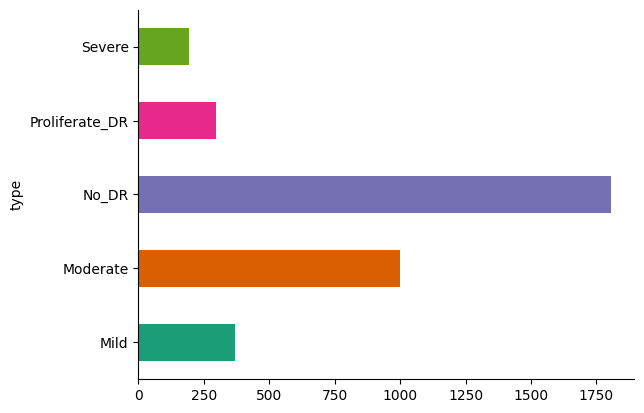

In [ ]:
# @title type

from matplotlib import pyplot as plt
import seaborn as sns
df.groupby('type').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

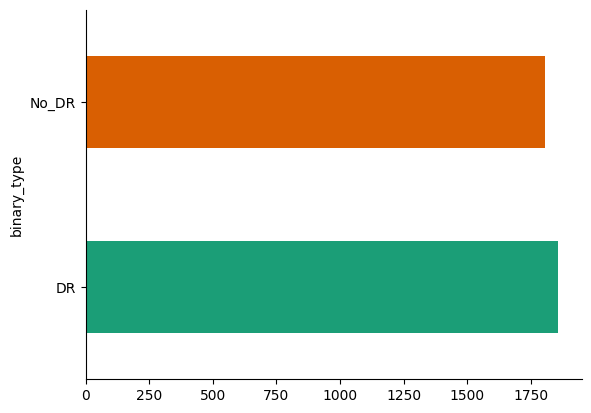

In [ ]:
# @title binary_type

from matplotlib import pyplot as plt
import seaborn as sns
df.groupby('binary_type').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


<Axes: >

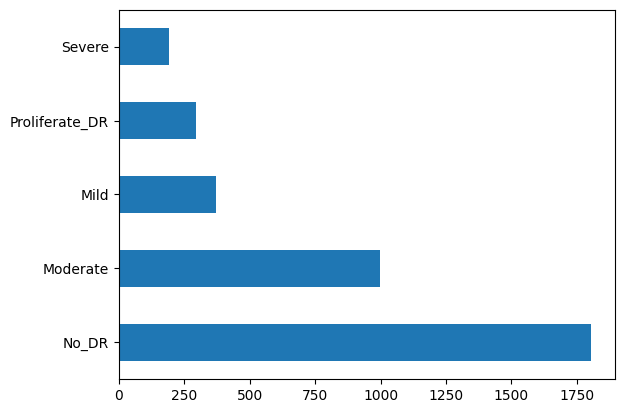

In [ ]:
df['type'].value_counts().plot(kind='barh')


<Axes: >

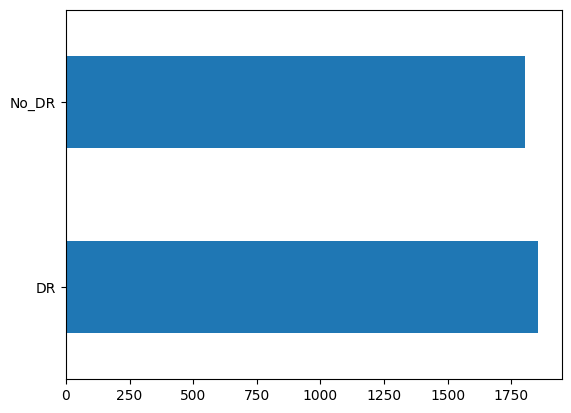

In [ ]:
df['binary_type'].value_counts().plot(kind='barh')


In [ ]:
# df.index.names = ['index_level', 'diagnosis']


In [ ]:
#Using dataframe df: balanced the 5 types of DR and undersampled the dataset

df.groupby('binary_type').apply(lambda x: x.sample(df.groupby('binary_type').size().min())).reset_index(drop=True)


,id_code,diagnosis,binary_type,type
0,f481f76a6b75,1,DR,Mild
1,6630f8675a97,4,DR,Proliferate_DR
2,a790a3b36390,2,DR,Moderate
3,384631079d1e,1,DR,Mild
4,657859f893d9,2,DR,Moderate
...,...,...,...,...
3605,0a902c80d5da,0,No_DR,No_DR
3606,f8f5942b690e,0,No_DR,No_DR
3607,3cdef7c591cc,0,No_DR,No_DR
3608,2b5bb6d33959,0,No_DR,No_DR


NameError: name '_df_47' is not defined

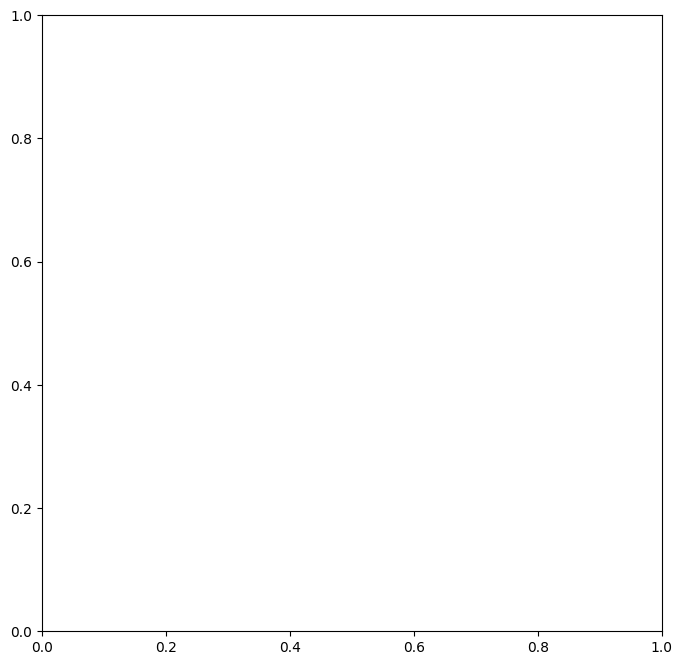

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
import pandas as pd
plt.subplots(figsize=(8, 8))
df_2dhist = pd.DataFrame({
    x_label: grp['type'].value_counts()
    for x_label, grp in _df_47.groupby('binary_type')
})
sns.heatmap(df_2dhist, cmap='viridis')
plt.xlabel('binary_type')
_ = plt.ylabel('type')

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
_df_45.groupby('type').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
_df_44.groupby('binary_type').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
from matplotlib import pyplot as plt
_df_43['diagnosis'].plot(kind='hist', bins=20, title='diagnosis')
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
# prompt: plot the data after balancing

df['type'].value_counts().plot(kind='barh')


In [ ]:
from matplotlib import pyplot as plt
import seaborn as sns
_df_1.groupby('binary_type').size().plot(kind='barh', color=sns.palettes.mpl_palette('Dark2'))
plt.gca().spines[['top', 'right',]].set_visible(False)

In [ ]:
# Split into stratified train, val, and test sets
train_intermediate, val = train_test_split(df, test_size = 0.15, stratify = df['type'])
train, test = train_test_split(train_intermediate, test_size = 0.15 / (1 - 0.15), stratify = train_intermediate['type'])

print(train['type'].value_counts(), '\n')
print(test['type'].value_counts(), '\n')
print(val['type'].value_counts(), '\n')

In [ ]:
# Create working directories for train/val/test
base_dir = ''

train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

if os.path.exists(base_dir):
    shutil.rmtree(base_dir)

if os.path.exists(train_dir):
    shutil.rmtree(train_dir)
os.makedirs(train_dir)

if os.path.exists(val_dir):
    shutil.rmtree(val_dir)
os.makedirs(val_dir)

if os.path.exists(test_dir):
    shutil.rmtree(test_dir)
os.makedirs(test_dir)


In [ ]:
# Set the batch size and image dimensions
batch_size = 32
img_height = 128  # Change image height to 128
img_width = 128  # Change image width to 128


In [ ]:
# Data Augmentation for the training set with resizing
train_datagen = ImageDataGenerator(
    rescale=1./255,
    rotation_range=40,
    width_shift_range=0.2,
    height_shift_range=0.2,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True,
    fill_mode='nearest')

In [ ]:
# Data Augmentation for the validation and test sets with resizing
val_test_datagen = ImageDataGenerator(rescale=1./255)


In [ ]:
# Copy images to respective working directory
src_dir = r'/content/drive/MyDrive/APTOS2019_gaussianfiltered/gaussian_filtered_images/gaussian_filtered_images'
for index, row in train.iterrows():
    diagnosis = row['type']
    binary_diagnosis = row['binary_type']
    id_code = row['id_code'] + ".png"
    srcfile = os.path.join(src_dir, diagnosis, id_code)
    dstfile = os.path.join(train_dir, binary_diagnosis)
    os.makedirs(dstfile, exist_ok = True)
    shutil.copy(srcfile, dstfile)

for index, row in val.iterrows():
    diagnosis = row['type']
    binary_diagnosis = row['binary_type']
    id_code = row['id_code'] + ".png"
    srcfile = os.path.join(src_dir, diagnosis, id_code)
    dstfile = os.path.join(val_dir, binary_diagnosis)
    os.makedirs(dstfile, exist_ok = True)
    shutil.copy(srcfile, dstfile)

for index, row in test.iterrows():
    diagnosis = row['type']
    binary_diagnosis = row['binary_type']
    id_code = row['id_code'] + ".png"
    srcfile = os.path.join(src_dir, diagnosis, id_code)
    dstfile = os.path.join(test_dir, binary_diagnosis)
    os.makedirs(dstfile, exist_ok = True)
    shutil.copy(srcfile, dstfile)

In [ ]:
# Setting up ImageDataGenerator for train/val/test

train_path = 'train'
val_path = 'val'
test_path = 'test'

train_batches = ImageDataGenerator(rescale = 1./255).flow_from_directory(train_path, target_size=(128,128), shuffle = True)
val_batches = ImageDataGenerator(rescale = 1./255).flow_from_directory(val_path, target_size=(128,128), shuffle = True)
test_batches = ImageDataGenerator(rescale = 1./255).flow_from_directory(test_path, target_size=(128,128), shuffle = False)


In [ ]:
# Building the model

model = tf.keras.Sequential([
    layers.Conv2D(8, (3,3), padding="valid", input_shape=(128,128,3), activation = 'relu'),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.BatchNormalization(),

    layers.Conv2D(16, (3,3), padding="valid", activation = 'relu'),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.BatchNormalization(),

    layers.Conv2D(32, (4,4), padding="valid", activation = 'relu'),
    layers.MaxPooling2D(pool_size=(2,2)),
    layers.BatchNormalization(),

    layers.Flatten(),
    layers.Dense(32, activation = 'relu'),
    layers.Dropout(0.15),
    layers.Dense(2, activation = 'softmax')
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss=tf.keras.losses.BinaryCrossentropy(),
              metrics=['acc'])

history = model.fit(train_batches,
                    epochs=30,
                    validation_data=val_batches)

In [ ]:
model.save('64x3-CNN1.model')
print(os.getcwd())


In [ ]:
loss, acc = model.evaluate_generator(test_batches, verbose=1)
# print("Loss: ", loss)
print("Accuracy: ", acc)


In [ ]:
!pip install scikit-learn

from sklearn.metrics import confusion_matrix, accuracy_score, precision_score, recall_score, f1_score

y_true = test_batches.classes
y_pred = model.predict(test_batches, verbose=1)
y_pred = np.argmax(y_pred, axis=1)

confusion_matrix = confusion_matrix(y_true, y_pred)
print(confusion_matrix)

accuracy = accuracy_score(y_true, y_pred)
print("Accuracy:", accuracy)

precision = precision_score(y_true, y_pred)
print("Precision:", precision)

recall = recall_score(y_true, y_pred)
print("Recall:", recall)

f1score = f1_score(y_true, y_pred)
print("F1 score:", f1score)

# Calculate specificity
tn, fp, fn, tp = confusion_matrix.ravel()
specificity = tn / (tn + fp)
print("Specificity:", specificity)

# Plot confusion matrix
plt.imshow(confusion_matrix, cmap=plt.cm.Blues)
plt.colorbar()
plt.xlabel("Predicted class")
plt.ylabel("True class")
plt.xticks([0, 1], ["Healthy", "Diabetic"])
plt.yticks([0, 1], ["Healthy", "Diabetic"])
plt.title("Confusion matrix")
plt.show()
